In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)  # don't truncate long cell contents

In [2]:
import re
from concurrent.futures import ThreadPoolExecutor
from glob import glob
from os.path import basename, dirname

# ---------------------------------------------------------------- parsing ---

_FIELD_RE = re.compile(r"^\s*([A-Za-z][^:]*?)\s*:\s*(.*?)\s*$")
_MISSING = {"", "-", "n/a", "na", "none", "null"}


def _to_bool(v):
    return v.strip().lower() in {"yes", "true", "1"}


def _to_seconds(v):
    return float(v.split()[0])


# report label -> (dict key, caster)
_FIELDS = {
    "Item Index":                          ("item_index", int),
    "JSON Path":                           ("json_path", str),
    "Embedding Path":                      ("embedding_path", str),
    "JSON Valid":                          ("json_valid", _to_bool),
    "Sequence Similarity (Gestalt)*":      ("sequence_similarity", float),
    "Levenshtein Distance (minified)":     ("levenshtein_distance", int),
    "Levenshtein Similarity (minified)*":  ("levenshtein_similarity", float),
    "App Match":                           ("app_match", _to_bool),
    "Activity Match":                      ("activity_match", _to_bool),
    "Component Count (GT)":                ("component_count_gt", int),
    "Component Count (Pred)":              ("component_count_pred", int),
    "Class Accuracy*":                     ("class_accuracy", float),
    "Average Bounds IoU*":                 ("average_bounds_iou", float),
    "Execution Time":                      ("execution_time", _to_seconds),
}


def parse_metrics_from_report_file(path):
    """Parse an evaluation report into a flat dict of metrics.

    The side-by-side JSON dump is skipped entirely; missing or unparsable
    values become None so every report yields the same set of keys.
    """
    with open(path, "r", encoding="utf-8", errors="replace") as fh:
        text = fh.read()

    # header (above the JSON table) + everything below "METRICS:"
    head, sep, tail = text.partition("GROUND TRUTH")
    relevant = head + tail.partition("METRICS:")[2] if sep else text

    out = {key: None for key, _ in _FIELDS.values()}
    for line in relevant.splitlines():
        match = _FIELD_RE.match(line)
        if match is None:
            continue
        label, raw = match.group(1), match.group(2)
        if label not in _FIELDS:
            continue
        key, cast = _FIELDS[label]
        if raw.lower() in _MISSING:
            continue
        try:
            out[key] = cast(raw)
        except (ValueError, IndexError):
            out[key] = None
    return out


def _process_report(g):
    # e.g. "reconstructions_4096_avg/0_report.txt" -> "4096_avg"
    # e.g. "reconstructions_4096_last/0_report.txt" -> "4096_last"
    # keeping the pooling suffix (avg/last) in the key prevents the
    # 4096_avg and 4096_last folders from clobbering each other.
    dimensions = dirname(g).removeprefix("reconstructions_")
    idx = basename(g).split("_")[0]
    return (dimensions, idx), parse_metrics_from_report_file(g)


# ------------------------------------------------------------------- entry ---

def parse_reconstruction_dataset(pattern="reconstructions*/*", max_workers=None):
    """Glob reconstruction report files and parse them in parallel.

    Returns a dict keyed by (dimensions, idx) -> metrics dict.
    """
    paths = [g for g in glob(pattern) if "report" in g]

    results = {}
    with ThreadPoolExecutor(max_workers=max_workers) as pool:
        for key, metrics in pool.map(_process_report, paths, chunksize=8):
            results[key] = metrics

    return results

In [3]:
results = parse_reconstruction_dataset()

df = pd.DataFrame(results).T
df.index.names = ['dim', 'idx']

In [4]:
idx_per_dim = df.index.to_frame(index=False).groupby('dim')['idx'].apply(set)
common_idx = set.intersection(*idx_per_dim)

df = df.loc[df.index.get_level_values('idx').isin(common_idx)]

## Filters

In [5]:
# remove overtrained adapter
df = df[(df.index.get_level_values('dim') != '128x4096_avg')]

# Take only validation set jsons into account
df = df[(df.index.get_level_values('idx').astype(int) > 11504)]

# Take only valid jsons into account across all dimensions
df = df[df.groupby(level='idx')['json_valid'].transform('all')]

In [6]:
df

item_index                             json_path  \
dim         idx                                                      
16x4096_avg 11510      11510  ../rico-data/data/layouts/11510.json   
            11558      11558  ../rico-data/data/layouts/11558.json   
            11616      11616  ../rico-data/data/layouts/11616.json   
            11657      11657  ../rico-data/data/layouts/11657.json   
            11710      11710  ../rico-data/data/layouts/11710.json   
...                      ...                                   ...   
8x4096_avg  11710      11710  ../rico-data/data/layouts/11710.json   
            11766      11766  ../rico-data/data/layouts/11766.json   
            11841      11841  ../rico-data/data/layouts/11841.json   
            11856      11856  ../rico-data/data/layouts/11856.json   
            11894      11894  ../rico-data/data/layouts/11894.json   

                                     embedding_path json_valid  \
dim         idx                                                  
16x4096_avg 11510  embeddings_16x4096_avg/11510.npz       True   
            11558  embeddings_16x4096_avg/11558.npz       True   
            11616  embeddings_16x4096_avg/11616.npz       True   
            11657  embeddings_16x4096_avg/11657.npz       True   
            11710  embeddings_16x4096_avg/11710.npz       True   
...                                             ...        ...   
8x4096_avg  11710   embeddings_8x4096_avg/11710.npz       True   
            11766   embeddings_8x4096_avg/11766.npz       True   
            11841   embeddings_8x4096_avg/11841.npz       True   
            11856   embeddings_8x4096_avg/11856.npz       True   
            11894   embeddings_8x4096_avg/11894.npz       True   

                  sequence_similarity levenshtein_distance  \
dim         idx                                              
16x4096_avg 11510                 1.0                    0   
            11558                 1.0                    0   
            11616              0.8151                   46   
            11657                 1.0                    0   
            11710              0.2547                   24   
...                               ...                  ...   
8x4096_avg  11710              0.9573                   22   
            11766              0.5846                   82   
            11841                 1.0                    0   
            11856              0.1249                  359   
            11894              0.1127                 1396   

                  levenshtein_similarity app_match activity_match  \
dim         idx                                                     
16x4096_avg 11510                    1.0      True           True   
            11558                    1.0      True           True   
            11616                 0.7178     False          False   
            11657                    1.0      True           True   
            11710                 0.9589     False           True   
...                                  ...       ...            ...   
8x4096_avg  11710                 0.9625     False           True   
            11766                 0.5148     False          False   
            11841                    1.0      True           True   
            11856                 0.3997     False          False   
            11894                 0.3207     False          False   

                  component_count_gt component_count_pred class_accuracy  \
dim         idx                                                            
16x4096_avg 11510                  1                    1            1.0   
            11558                  1                    1            1.0   
            11616                  1                    1            1.0   
            11657                  1                    1            1.0   
            11710                  5                    5            0.6   
...        

In [7]:
df.columns

Index(['item_index', 'json_path', 'embedding_path', 'json_valid',
       'sequence_similarity', 'levenshtein_distance', 'levenshtein_similarity',
       'app_match', 'activity_match', 'component_count_gt',
       'component_count_pred', 'class_accuracy', 'average_bounds_iou',
       'execution_time'],
      dtype='str')

In [8]:
df.groupby("dim").count()

,item_index,json_path,embedding_path,json_valid,sequence_similarity,levenshtein_distance,levenshtein_similarity,app_match,activity_match,component_count_gt,component_count_pred,class_accuracy,average_bounds_iou,execution_time
dim,,,,,,,,,,,,,,
16x4096_avg,9,9,9,9,9,9,9,9,9,9,9,9,9,9
32x4096_avg,9,9,9,9,9,9,9,9,9,9,9,9,9,9
4096_avg,9,9,9,9,9,9,9,9,9,9,9,9,9,9
4096_last,9,9,9,9,9,9,9,9,9,9,9,9,9,9
4x4096_avg,9,9,9,9,9,9,9,9,9,9,9,9,9,9
64x4096_avg,9,9,9,9,9,9,9,9,9,9,9,9,9,9
8x4096_avg,9,9,9,9,9,9,9,9,9,9,9,9,9,9


In [9]:
def show_stats(column: str):
    global df
    df[column] = pd.to_numeric(df[column], errors='coerce')
    df.boxplot(column=column, by='dim', showfliers=False, figsize=(8,6))
    plt.xticks(rotation=45)

    # Deskriptive Statistiken pro Gruppe
    desc_stats = df.groupby('dim')[column].describe()
    desc_stats['median'] = df.groupby('dim')[column].median()
    desc_stats['IQR'] = df.groupby('dim')[column].quantile(0.75) - df.groupby('dim')[column].quantile(0.25)
    print(desc_stats)

def plot_bool_grouped(df: pd.DataFrame, bool_cols: list, by: str, as_percentage: bool = True):
    """
    Plottet den Anteil von True für mehrere Spalten gruppiert nach einer Kategorie.

    :param df: Pandas DataFrame
    :param bool_cols: Liste der True/False-Spalten
    :param by: Spaltenname oder Index-Level für die Gruppierung (z.B. 'dim')
    :param as_percentage: True für Prozent (0-100%), False für absolute Anzahl
    """
    # Falls 'by' im Index liegt, den Index auflösen
    data = df.reset_index() if (by in df.index.names and by not in df.columns) else df.copy()

    if as_percentage:
        grouped = data.groupby(by)[bool_cols].mean() * 100
        errors = data.groupby(by)[bool_cols].sem() * 100
        ylabel = 'Anteil True (%)'
    else:
        grouped = data.groupby(by)[bool_cols].sum()
        errors = data.groupby(by)[bool_cols].std()
        ylabel = 'Anzahl True'

    ax = grouped.plot(kind='bar', capsize=4, figsize=(9, 5))

    plt.ylabel(ylabel)
    plt.xlabel(by)
    plt.title(f'True-Verteilung gruppiert nach "{by}"')
    plt.xticks(rotation=45)
    plt.legend(title='Spalten', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

In [10]:
df.groupby('dim').count()

,item_index,json_path,embedding_path,json_valid,sequence_similarity,levenshtein_distance,levenshtein_similarity,app_match,activity_match,component_count_gt,component_count_pred,class_accuracy,average_bounds_iou,execution_time
dim,,,,,,,,,,,,,,
16x4096_avg,9,9,9,9,9,9,9,9,9,9,9,9,9,9
32x4096_avg,9,9,9,9,9,9,9,9,9,9,9,9,9,9
4096_avg,9,9,9,9,9,9,9,9,9,9,9,9,9,9
4096_last,9,9,9,9,9,9,9,9,9,9,9,9,9,9
4x4096_avg,9,9,9,9,9,9,9,9,9,9,9,9,9,9
64x4096_avg,9,9,9,9,9,9,9,9,9,9,9,9,9,9
8x4096_avg,9,9,9,9,9,9,9,9,9,9,9,9,9,9


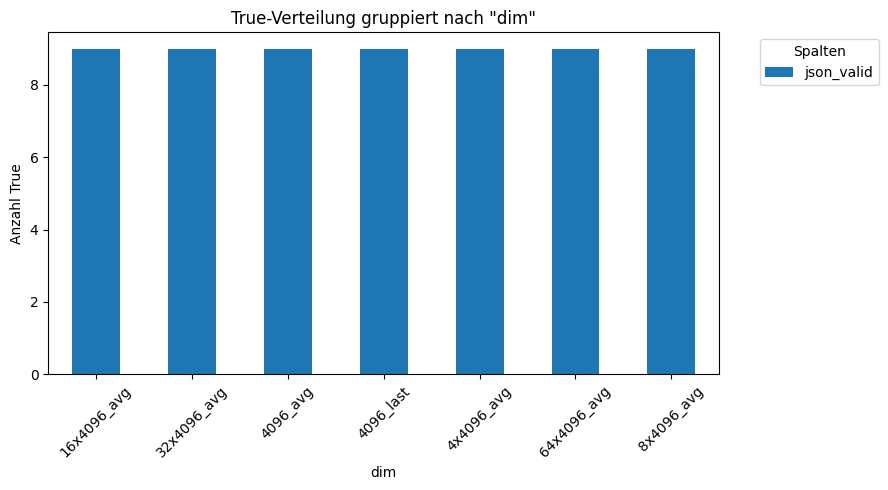

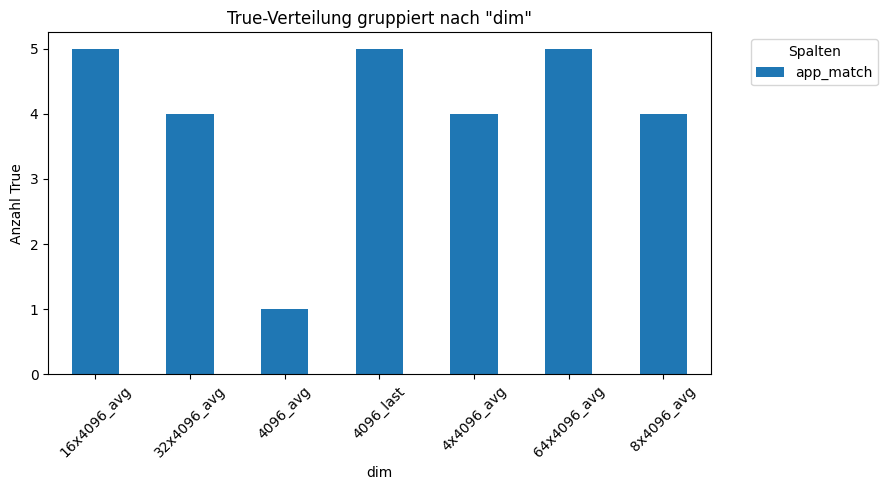

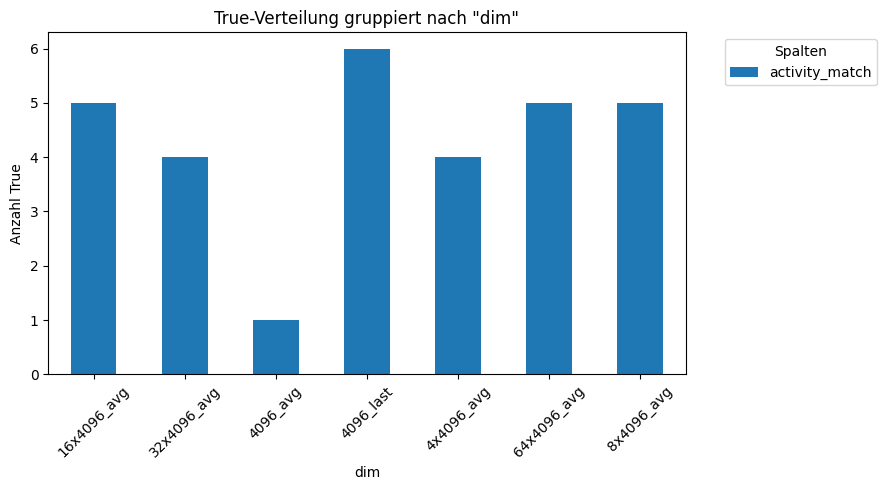

In [11]:
plot_bool_grouped(df, ['json_valid'], by="dim", as_percentage=False)
plot_bool_grouped(df, ['app_match'], by="dim", as_percentage=False)
plot_bool_grouped(df, ['activity_match'], by="dim", as_percentage=False)

             count      mean       std     min     25%     50%     75%  max  \
dim                                                                           
16x4096_avg    9.0  0.714033  0.330841  0.2105  0.4426  0.8151  1.0000  1.0   
32x4096_avg    9.0  0.588878  0.409165  0.0496  0.1942  0.4715  1.0000  1.0   
4096_avg       9.0  0.469356  0.316264  0.0674  0.1597  0.5707  0.5707  1.0   
4096_last      9.0  0.559078  0.422591  0.1293  0.1547  0.3043  1.0000  1.0   
4x4096_avg     9.0  0.557056  0.441495  0.0788  0.1176  0.5365  1.0000  1.0   
64x4096_avg    9.0  0.708889  0.339426  0.2240  0.3529  0.8041  1.0000  1.0   
8x4096_avg     9.0  0.711833  0.374041  0.1127  0.5846  0.9573  1.0000  1.0   

             median     IQR  
dim                          
16x4096_avg  0.8151  0.5574  
32x4096_avg  0.4715  0.8058  
4096_avg     0.5707  0.4110  
4096_last    0.3043  0.8453  
4x4096_avg   0.5365  0.8824  
64x4096_avg  0.8041  0.6471  
8x4096_avg   0.9573  0.4154  


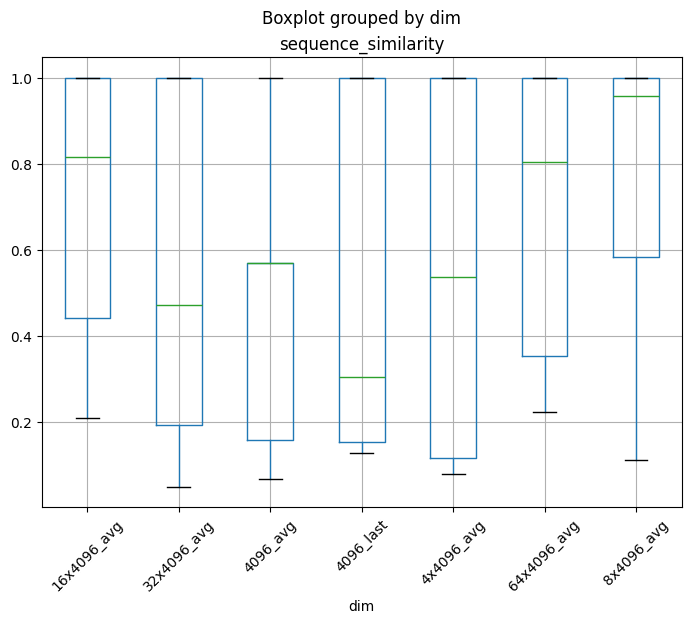

In [12]:
show_stats('sequence_similarity')

             count        mean         std  min    25%    50%     75%     max  \
dim                                                                             
16x4096_avg    9.0   89.888889  142.287073  0.0    0.0   24.0    64.0   344.0   
32x4096_avg    9.0  210.333333  213.517564  0.0    0.0  242.0   363.0   533.0   
4096_avg       9.0  493.555556  606.907759  0.0  108.0  108.0  1041.0  1416.0   
4096_last      9.0  357.000000  505.378818  0.0    0.0   23.0   624.0  1439.0   
4x4096_avg     9.0  412.666667  487.233004  0.0    0.0  109.0   853.0  1128.0   
64x4096_avg    9.0   94.888889  163.570661  0.0    0.0   22.0    70.0   483.0   
8x4096_avg     9.0  214.666667  457.643147  0.0    0.0   22.0    82.0  1396.0   

             median    IQR  
dim                         
16x4096_avg    24.0   64.0  
32x4096_avg   242.0  363.0  
4096_avg      108.0  933.0  
4096_last      23.0  624.0  
4x4096_avg    109.0  853.0  
64x4096_avg    22.0   70.0  
8x4096_avg     22.0   82.0  


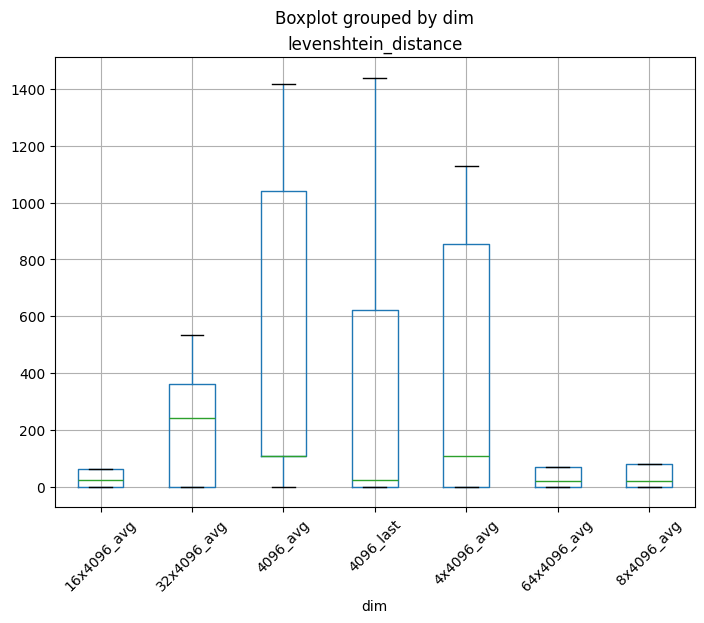

In [13]:
show_stats('levenshtein_distance')

             count      mean       std     min     25%     50%     75%  max  \
dim                                                                           
16x4096_avg    9.0  0.819967  0.215776  0.4465  0.6352  0.9589  1.0000  1.0   
32x4096_avg    9.0  0.636800  0.348217  0.2680  0.3529  0.4348  1.0000  1.0   
4096_avg       9.0  0.469456  0.242646  0.2164  0.3636  0.4545  0.4545  1.0   
4096_last      9.0  0.648578  0.416672  0.0927  0.1907  0.9606  1.0000  1.0   
4x4096_avg     9.0  0.625511  0.368441  0.1194  0.3622  0.4930  1.0000  1.0   
64x4096_avg    9.0  0.804289  0.273703  0.1923  0.7178  0.9623  1.0000  1.0   
8x4096_avg     9.0  0.749978  0.295095  0.3207  0.5148  0.9625  1.0000  1.0   

             median     IQR  
dim                          
16x4096_avg  0.9589  0.3648  
32x4096_avg  0.4348  0.6471  
4096_avg     0.4545  0.0909  
4096_last    0.9606  0.8093  
4x4096_avg   0.4930  0.6378  
64x4096_avg  0.9623  0.2822  
8x4096_avg   0.9625  0.4852  


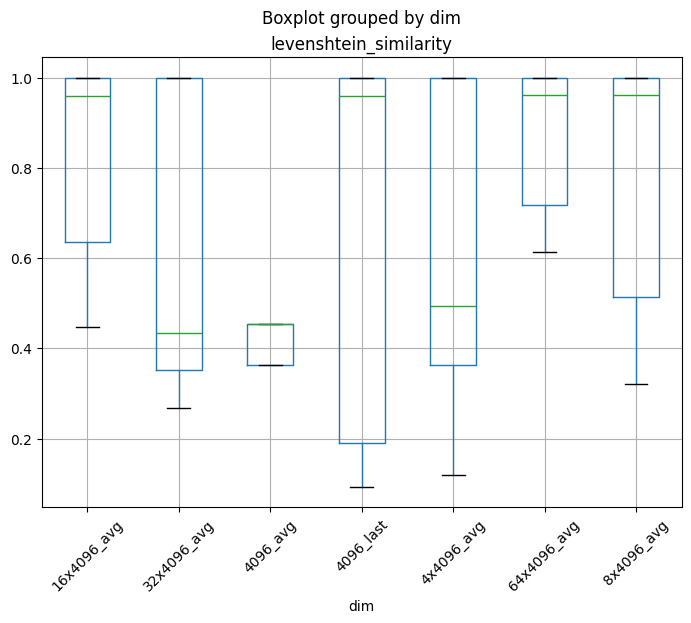

In [14]:
show_stats('levenshtein_similarity')

             count      mean       std  min     25%  50%  75%  max  median  \
dim                                                                          
16x4096_avg    9.0  0.622222  0.484195  0.0  0.0000  1.0  1.0  1.0     1.0   
32x4096_avg    9.0  0.444444  0.527046  0.0  0.0000  0.0  1.0  1.0     0.0   
4096_avg       9.0  0.111111  0.333333  0.0  0.0000  0.0  0.0  1.0     0.0   
4096_last      9.0  0.733333  0.435890  0.0  0.6000  1.0  1.0  1.0     1.0   
4x4096_avg     9.0  0.555556  0.527046  0.0  0.0000  1.0  1.0  1.0     1.0   
64x4096_avg    9.0  0.728400  0.437834  0.0  0.5556  1.0  1.0  1.0     1.0   
8x4096_avg     9.0  0.511111  0.501110  0.0  0.0000  0.6  1.0  1.0     0.6   

                IQR  
dim                  
16x4096_avg  1.0000  
32x4096_avg  1.0000  
4096_avg     0.0000  
4096_last    0.4000  
4x4096_avg   1.0000  
64x4096_avg  0.4444  
8x4096_avg   1.0000  


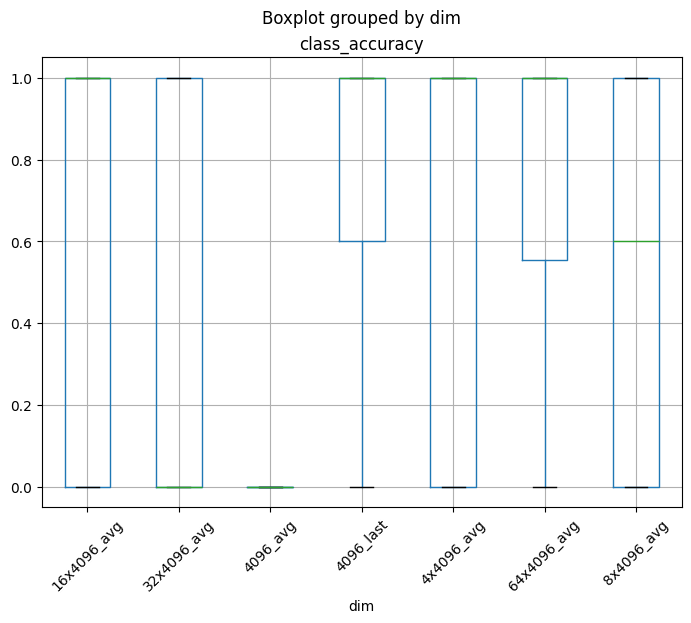

In [15]:
show_stats('class_accuracy')

             count      mean       std     min     25%     50%     75%  max  \
dim                                                                           
16x4096_avg    9.0  0.817244  0.302599  0.0990  0.7697  0.9697  1.0000  1.0   
32x4096_avg    9.0  0.518567  0.481968  0.0014  0.0606  0.5202  1.0000  1.0   
4096_avg       9.0  0.648211  0.388558  0.0090  0.2202  0.9091  0.9091  1.0   
4096_last      9.0  0.719133  0.409671  0.0076  0.6330  1.0000  1.0000  1.0   
4x4096_avg     9.0  0.603133  0.457614  0.0051  0.2242  0.9175  1.0000  1.0   
64x4096_avg    9.0  0.693322  0.417733  0.0000  0.3333  1.0000  1.0000  1.0   
8x4096_avg     9.0  0.740200  0.410473  0.0032  0.7697  0.9175  1.0000  1.0   

             median     IQR  
dim                          
16x4096_avg  0.9697  0.2303  
32x4096_avg  0.5202  0.9394  
4096_avg     0.9091  0.6889  
4096_last    1.0000  0.3670  
4x4096_avg   0.9175  0.7758  
64x4096_avg  1.0000  0.6667  
8x4096_avg   0.9175  0.2303  


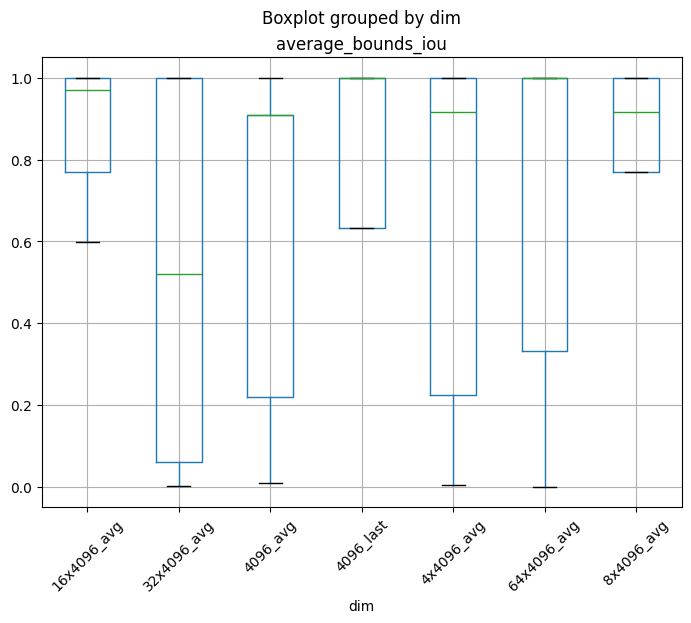

In [16]:
show_stats('average_bounds_iou')